# Random-state baselines for Φ: surrogate and null-ensemble tests

A companion to the coupling search (`Spin_Phi_Optimization.ipynb`; notebooks 03–05 in the repository) and to the analytical note `phi_analytical_calculation.pdf`. Equation numbers below refer to that note. References to "the main notebook" mean the coupling search. The notebook is self-contained: it does not import or run anything from the other notebooks. The follow-up analysis of energy conservation is in `Phi_Energy_Conservation.ipynb` (notebook 07 in the repository).

**Observable.** Φ = Tr[(ρ − ρ′)²] for the reduced states of an m-dimensional block (m = d_A) inside an n-dimensional environment (n = d_B). In the project, m = 2^(ℓ+1) and n = 2^(L−ℓ−1). Φ is averaged over adjacent eigenvector pairs in the middle half of the spectrum and over all L − ℓ block positions.

| Test | Question | Kind of result |
|---|---|---|
| 0 | Can a product state ρ_A ⊗ \|ψ_B⟩⟨ψ_B\|, with ψ_B drawn from GOE/GUE, act as a random-state surrogate? | Demonstration: no, because B drops out of Φ |
| 1 | Qubit: does a Gaussian Bloch vector with matched mean and covariance reproduce the exact finite-n law, eq. (27)? | Comparison with the exact law |
| 2 | At the project's block sizes (m/n = ½), is the per-pair law close to the matched χ² law, eq. (36)? | The open question in PDF §12 |
| 3 | What is the null distribution of the **averaged** project observable for structureless (Haar / GOE / GUE) eigenbases? | Reference null for the Hamiltonian/random ratio |
| 3b | Do the two ways of sampling that null (QR and GOE diagonalisation) agree at 2,000 draws each? | Cross-check |
| 4 | Example: a Hamiltonian (the PRX point) compared with the null from test 3 | How to use the null |

**Two kinds of output.**
- `[PASS]` / `[FAIL]` lines are checks that must hold if the code and the formulas are correct, such as sampled means against exact means. The summary at the end collects them. Statistical checks require |z| < 4, or a KS p-value above 10⁻³ when two samplers should agree.
- `FINDING` lines answer an open question. They have no expected value, so they cannot fail.

**Running.** Run all cells from top to bottom. With `QUICK = True` the sample sizes drop about fivefold and the notebook finishes in about 1 minute. With `QUICK = False` it does the full reference run, which took 5.1 minutes on this machine. The seed is fixed, so runs are reproducible.

In [1]:
import time
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.linalg import eigh
from IPython.display import display

# ---- Run configuration ------------------------------------------------------
QUICK = False        # True: ~5x fewer samples (~1 min). False: full reference run (~4-5 min).
SEED  = 20261123
rng   = np.random.default_rng(SEED)
SCALE = 0.2 if QUICK else 1.0

def n_samples(full):
    return max(2000, int(full * SCALE))

ENS = {False: 'real (GOE)', True: 'complex (GUE)'}

# ---- Plot style --------------------------------------------------------------
C_BLUE, C_ORANGE, C_AQUA, C_INK = '#2a78d6', '#eb6834', '#1baf7a', '#3d3d3a'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3dd', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a897f',
    'axes.labelcolor': C_INK, 'xtick.color': '#6b6a63', 'ytick.color': '#6b6a63',
    'lines.linewidth': 2, 'legend.frameon': False, 'axes.titlesize': 10, 'axes.labelsize': 9,
})

# ---- Check registry ----------------------------------------------------------
CHECKS = []
def check(name, passed, detail=''):
    CHECKS.append((name, bool(passed), detail))
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"   ({detail})" if detail else ''))

T_START = time.time()
print(f'QUICK = {QUICK}, seed = {SEED}')

QUICK = False, seed = 20261123


## Shared definitions

**Ensemble.** X is an m × n matrix of independent Gaussian entries: real for β = 1, or complex with E|X_ij|² = 1 for β = 2. The reduced state is ρ = XX†/Tr(XX†) (eq. 1), which is the marginal on A of a Haar-random pure state on A ⊗ B. Real states correspond to eigenvectors of real (GOE-class) Hamiltonians, and complex states to GUE-class Hamiltonians.

**Exact independent-pair statistics.** The mean μ is given by eq. (3). K, the number of real traceless coordinates, is given by eq. (2). The purity variance v_P is given by eq. (4), and the variance follows as Var Φ = 2v_P + μ²/K (eq. 5). The matched χ² approximation, eq. (36), is Φ ≈ (μ/K)·χ²_K, whose variance is 2μ²/K. For an orthonormal pair, such as adjacent eigenvectors, the mean becomes μ·D/(D−1) (eq. 39).

In [2]:
def gaussian(shape, cplx):
    # Standard real Gaussian (beta=1) or complex Gaussian with E|z|^2 = 1 (beta=2).
    if cplx:
        return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)
    return rng.standard_normal(shape)


def induced_states(m, n, cplx, N):
    # N reduced states rho = X X^dag / Tr(X X^dag), shape (N, m, m).  PDF eq. (1).
    X = gaussian((N, m, n), cplx)
    W = X @ np.conj(np.swapaxes(X, -1, -2))
    return W / np.real(np.trace(W, axis1=-2, axis2=-1))[:, None, None]


def hs_dist2(rho1, rho2):
    # Phi = Tr[(rho1 - rho2)^2] = sum_ij |Delta_ij|^2 for stacks of Hermitian matrices.
    return np.sum(np.abs(rho1 - rho2) ** 2, axis=(-2, -1))


def exact_phi(m, n, cplx, N, chunk_entries=2_000_000):
    # N independent-pair samples of Phi from the induced ensemble (no approximation).
    chunk = max(1, chunk_entries // (m * n))
    out = []
    for s in range(0, N, chunk):
        b = min(chunk, N - s)
        out.append(hs_dist2(induced_states(m, n, cplx, b), induced_states(m, n, cplx, b)))
    return np.concatenate(out)


def theory(m, n, cplx):
    # Exact independent-pair statistics: PDF eqs. (2)-(5), (36), (39).
    D = m * n
    if cplx:
        K  = m * m - 1
        mu = 2 * (m * m - 1) / (m * (D + 1))
        vP = 2 * (m * m - 1) * (n * n - 1) / ((D + 1) ** 2 * (D + 2) * (D + 3))
    else:
        K  = (m - 1) * (m + 2) // 2
        mu = 2 * (m + 2) * (m - 1) / (m * (D + 2))
        vP = 4 * (m - 1) * (m + 2) * (n - 1) * (n + 2) / ((D + 2) ** 2 * (D + 4) * (D + 6))
    return dict(m=m, n=n, D=D, K=K, mu=mu, vP=vP, var=2 * vP + mu ** 2 / K,
                var_chi2=2 * mu ** 2 / K, mu_orth=mu * D / (D - 1) if D > 1 else np.nan)


def mean_z(x, mu):
    # z-score of the sample mean against an exact mean.
    return (x.mean() - mu) / (x.std(ddof=1) / np.sqrt(len(x)))


def var_z(x, var):
    # z-score of the sample variance against an exact variance (s.e. from the 4th central moment).
    c = x - x.mean()
    m2, m4 = np.mean(c ** 2), np.mean(c ** 4)
    return (m2 - var) / np.sqrt((m4 - m2 ** 2) / len(x))


# ---- Formula sanity checks against values quoted in the PDF ---------------------
t = theory(2, 8, False)
check('Formulas: real qubit n=8 gives mean 2/9, var 4/99 (eq. 31)',
      np.isclose(t['mu'], 2 / 9) and np.isclose(t['var'], 4 / 99))
t = theory(2, 8, True)
check('Formulas: complex qubit n=8 gives mean 3/17, var 99/5491 (eq. 31)',
      np.isclose(t['mu'], 3 / 17) and np.isclose(t['var'], 99 / 5491))
for (m, n, muR, muC) in [(16, 32, 0.065661479, 0.062134503),
                         (32, 64, 0.032134146, 0.031204246),
                         (64, 128, 0.015857640, 0.015619279)]:
    check(f'Formulas: project baseline means for (m, n) = ({m}, {n}) match PDF §9 table',
          np.isclose(theory(m, n, False)['mu'], muR, atol=1e-9) and
          np.isclose(theory(m, n, True)['mu'], muC, atol=1e-9))

[PASS] Formulas: real qubit n=8 gives mean 2/9, var 4/99 (eq. 31)
[PASS] Formulas: complex qubit n=8 gives mean 3/17, var 99/5491 (eq. 31)
[PASS] Formulas: project baseline means for (m, n) = (16, 32) match PDF §9 table
[PASS] Formulas: project baseline means for (m, n) = (32, 64) match PDF §9 table
[PASS] Formulas: project baseline means for (m, n) = (64, 128) match PDF §9 table


## Test 0: Why a single product state can't be the surrogate

**Proposed construction.** Draw a state on A and a state ψ_B on B from GOE/GUE, form ρ_A ⊗ |ψ_B⟩⟨ψ_B|, and compute Φ on A.

**Why it fails.** Φ depends only on ρ_A = Tr_B(·). For a product state the partial trace returns ρ_A exactly, so whatever was drawn on B drops out, and Φ simply inherits the distribution put into ρ_A. If the global product state is pure, then ρ_A is pure and Φ follows the n = 1 law (eq. 29): arcsine for real states, uniform for complex states, with mean 1. That is the opposite of thermal. A small block looks thermal only because it is **entangled** with B.

**The correct A ⊗ B construction.** Take |ψ⟩ = Σᵢ |i⟩_A ⊗ |xᵢ⟩_B with independent Gaussian vectors xᵢ on B. This is a superposition of m product states, not a single one. It gives ρ_A equal to the Gram matrix of the xᵢ, which is XX†/Tr, the induced ensemble used in every later test.

**This cell:**
- (a) Checks that Tr_B[ρ_A ⊗ |ψ_B⟩⟨ψ_B|] = ρ_A for several GOE/GUE draws of ψ_B.
- (b) Samples pure product pairs |a⟩|b⟩, with a Haar-random on the qubit and b a GOE/GUE eigenvector on B. It compares them with entangled states of the same dimensions, using eq. (29) and eq. (31) respectively.

[PASS] Test 0a real (GOE): Tr_B[rho_A (x) |psi_B><psi_B|] = rho_A for 5 GOE/GUE draws of psi_B
[PASS] Test 0a complex (GUE): Tr_B[rho_A (x) |psi_B><psi_B|] = rho_A for 5 GOE/GUE draws of psi_B


[PASS] Test 0b real (GOE), pure product |a>|b>: sample mean and variance match theory   (z_mean = -0.03, z_var = -1.16)
[PASS] Test 0b real (GOE), entangled sum_i |i>|x_i>: sample mean and variance match theory   (z_mean = +0.64, z_var = -0.35)


[PASS] Test 0b complex (GUE), pure product |a>|b>: sample mean and variance match theory   (z_mean = -0.92, z_var = -0.29)
[PASS] Test 0b complex (GUE), entangled sum_i |i>|x_i>: sample mean and variance match theory   (z_mean = +0.84, z_var = -0.60)


,ensemble,state,pairs,mean,theory mean,var,theory var,theory
0,real (GOE),pure product |a>|b>,20000,0.99983,1.00000,0.49714,0.50000,"eq. (29), n = 1 law"
1,real (GOE),entangled sum_i |i>|x_i>,20000,0.06087,0.06061,0.00344,0.00346,"eq. (31), n = 32"
2,complex (GUE),pure product |a>|b>,20000,0.99627,1.00000,0.33274,0.33333,"eq. (29), n = 1 law"
3,complex (GUE),entangled sum_i |i>|x_i>,20000,0.04637,0.04615,0.00135,0.00137,"eq. (31), n = 32"


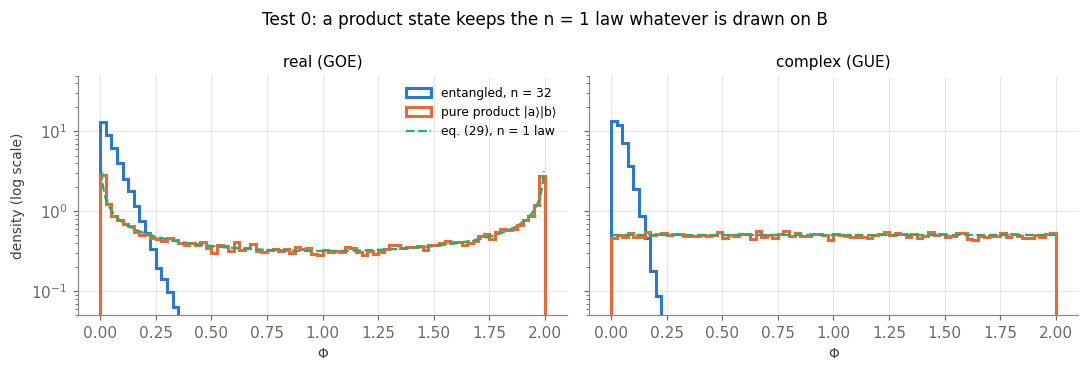

Test 0 time: 5.7 s


In [3]:
t0 = time.time()
n_B = 32                     # environment dimension for the demonstration (5 spins)
N0  = n_samples(20_000)


def middle_eigvecs(dim, cplx, N, chunk=2000):
    # One mid-spectrum eigenvector from each of N independent GOE (real) / GUE (complex) matrices.
    out = []
    for s in range(0, N, chunk):
        b = min(chunk, N - s)
        G = gaussian((b, dim, dim), cplx)
        H = (G + np.conj(np.swapaxes(G, -1, -2))) / 2
        out.append(np.linalg.eigh(H)[1][:, :, dim // 2])
    return np.concatenate(out)


def reduced_A(psi, dA, dB):
    # rho_A = Tr_B |psi><psi| for a stack of global vectors with the A index first.
    M = psi.reshape(-1, dA, dB)
    return M @ np.conj(np.swapaxes(M, -1, -2))


# (a) The B factor drops out of the reduced state.
for cplx in (False, True):
    rho_A = induced_states(2, 4, cplx, 1)[0]            # an arbitrary mixed qubit state
    ok = True
    for psi_B in middle_eigvecs(n_B, cplx, 5):
        rho_glob = np.kron(rho_A, np.outer(psi_B, psi_B.conj()))
        rho_back = np.einsum('iaja->ij', rho_glob.reshape(2, n_B, 2, n_B))   # trace over B
        ok &= np.allclose(rho_back, rho_A, atol=1e-13)
    check(f'Test 0a {ENS[cplx]}: Tr_B[rho_A (x) |psi_B><psi_B|] = rho_A for 5 GOE/GUE draws of psi_B', ok)

# (b) Pure product states vs entangled states with the same (d_A, d_B) = (2, n_B).
rows, hist0 = [], {}
for cplx in (False, True):
    a = gaussian((2, N0, 2), cplx)
    a /= np.linalg.norm(a, axis=-1, keepdims=True)                   # Haar-random qubit states
    b = np.stack([middle_eigvecs(n_B, cplx, N0) for _ in range(2)])  # GOE/GUE eigenvectors on B
    psi_prod = (a[..., :, None] * b[..., None, :]).reshape(2, N0, 2 * n_B)
    phi_prod = hs_dist2(reduced_A(psi_prod[0], 2, n_B), reduced_A(psi_prod[1], 2, n_B))

    psi_ent = gaussian((2, N0, 2 * n_B), cplx)                       # sum_i |i>_A |x_i>_B, normalised
    psi_ent /= np.linalg.norm(psi_ent, axis=-1, keepdims=True)
    phi_ent = hs_dist2(reduced_A(psi_ent[0], 2, n_B), reduced_A(psi_ent[1], 2, n_B))

    for label, ph, t in [('pure product |a>|b>', phi_prod, theory(2, 1, cplx)),
                         ('entangled sum_i |i>|x_i>', phi_ent, theory(2, n_B, cplx))]:
        zm, zv = mean_z(ph, t['mu']), var_z(ph, t['var'])
        check(f'Test 0b {ENS[cplx]}, {label}: sample mean and variance match theory',
              abs(zm) < 4 and abs(zv) < 4, f'z_mean = {zm:+.2f}, z_var = {zv:+.2f}')
        rows.append({'ensemble': ENS[cplx], 'state': label, 'pairs': len(ph),
                     'mean': ph.mean(), 'theory mean': t['mu'],
                     'var': ph.var(ddof=1), 'theory var': t['var'],
                     'theory': 'eq. (29), n = 1 law' if 'product' in label else f'eq. (31), n = {n_B}'})
    hist0[cplx] = (phi_prod, phi_ent)

display(pd.DataFrame(rows).round(5))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
bins = np.linspace(0, 2, 81)
grid = np.linspace(0.005, 1.995, 400)
for ax, cplx in zip(axes, (False, True)):
    phi_prod, phi_ent = hist0[cplx]
    ax.hist(phi_ent, bins, density=True, histtype='step', color=C_BLUE, lw=2,
            label=f'entangled, n = {n_B}')
    ax.hist(phi_prod, bins, density=True, histtype='step', color=C_ORANGE, lw=2,
            label='pure product |a⟩|b⟩')
    dens = 1 / (np.pi * np.sqrt(grid * (2 - grid))) if not cplx else 0.5 * np.ones_like(grid)
    ax.plot(grid, dens, color=C_AQUA, lw=1.5, ls='--', label='eq. (29), n = 1 law')
    ax.set_title(ENS[cplx]); ax.set_xlabel('Φ'); ax.set_yscale('log'); ax.set_ylim(0.05, 50)
axes[0].set_ylabel('density (log scale)'); axes[0].legend(loc='upper right', fontsize=8)
fig.suptitle('Test 0: a product state keeps the n = 1 law whatever is drawn on B', fontsize=11)
fig.tight_layout(); plt.show()
print(f'Test 0 time: {time.time() - t0:.1f} s')

## Test 1: Qubit, Gaussian Bloch-vector surrogate vs the exact law

**Surrogate.** Write ρ = (I + r·σ)/2 and draw r ~ N(0, s²·I_k), with k = 2 for real states and k = 3 for complex states. Set s² = μ/k so that E|r|² = EΦ = μ. The covariance of the Bloch coordinates is isotropic (eq. 15), so this matches both the mean and the covariance. It follows that Φ = ½|r − r′|² = (μ/k)·χ²_k exactly. **This surrogate is therefore the χ² approximation of eq. (36), written in Bloch coordinates.**

**Compared against:**
- (i) Exact samples from Gaussian X of size 2 × n.
- (ii) The exact finite-n recipe of eq. (27), with R ~ Beta as in eq. (26). Agreement between (i) and (ii) also verifies eq. (27).

**Expectation.** The surrogate should agree only as n → ∞ (eq. 35). At small n its variance is too large, its skewness stays at the χ²_k value, and some draws have |r| > 1, which is not a valid density matrix.

**Checks:**
- Exact-sample mean and variance against eqs. (30)–(31).
- A two-sample KS test between the Wishart samples (i) and the eq. (27) samples (ii).

[PASS] Test 1 real (GOE), n = 2: exact-sample mean and variance match eq. (31)   (z_mean = +1.25, z_var = +0.29)
[PASS] Test 1 real (GOE), n = 2: Wishart samples and eq. (27) samples have the same law   (KS D = 0.0022, p = 0.720)
[PASS] Test 1 real (GOE), n = 8: exact-sample mean and variance match eq. (31)   (z_mean = +0.91, z_var = +0.29)


[PASS] Test 1 real (GOE), n = 8: Wishart samples and eq. (27) samples have the same law   (KS D = 0.0026, p = 0.508)


[PASS] Test 1 real (GOE), n = 64: exact-sample mean and variance match eq. (31)   (z_mean = -0.82, z_var = -0.29)
[PASS] Test 1 real (GOE), n = 64: Wishart samples and eq. (27) samples have the same law   (KS D = 0.0015, p = 0.970)
[PASS] Test 1 complex (GUE), n = 2: exact-sample mean and variance match eq. (31)   (z_mean = +1.19, z_var = +1.55)
[PASS] Test 1 complex (GUE), n = 2: Wishart samples and eq. (27) samples have the same law   (KS D = 0.0018, p = 0.909)


[PASS] Test 1 complex (GUE), n = 8: exact-sample mean and variance match eq. (31)   (z_mean = -1.15, z_var = -0.63)
[PASS] Test 1 complex (GUE), n = 8: Wishart samples and eq. (27) samples have the same law   (KS D = 0.0022, p = 0.715)


[PASS] Test 1 complex (GUE), n = 64: exact-sample mean and variance match eq. (31)   (z_mean = -0.29, z_var = +0.14)
[PASS] Test 1 complex (GUE), n = 64: Wishart samples and eq. (27) samples have the same law   (KS D = 0.0025, p = 0.543)


,ensemble,n,pairs,mean (exact),var (exact),var surrogate / exact,skew exact,skew surrogate,KS D exact vs surrogate,surrogate |r|>1 (%)
0,real (GOE),2,200000,0.6667,0.2667,1.6667,0.6101,1.9768,0.0686,22.3310
1,real (GOE),8,200000,0.2222,0.0404,1.2222,1.4556,2.0272,0.0236,1.1365
2,real (GOE),64,200000,0.0308,0.0009,1.0308,1.9156,1.9873,0.0041,0.0000
3,complex (GUE),2,200000,0.6000,0.1543,1.5556,0.6503,1.6336,0.0556,17.2370
4,complex (GUE),8,200000,0.1765,0.0180,1.1515,1.3034,1.6040,0.0177,0.0672
5,complex (GUE),64,200000,0.0233,0.0004,1.0195,1.5784,1.6332,0.0034,0.0000


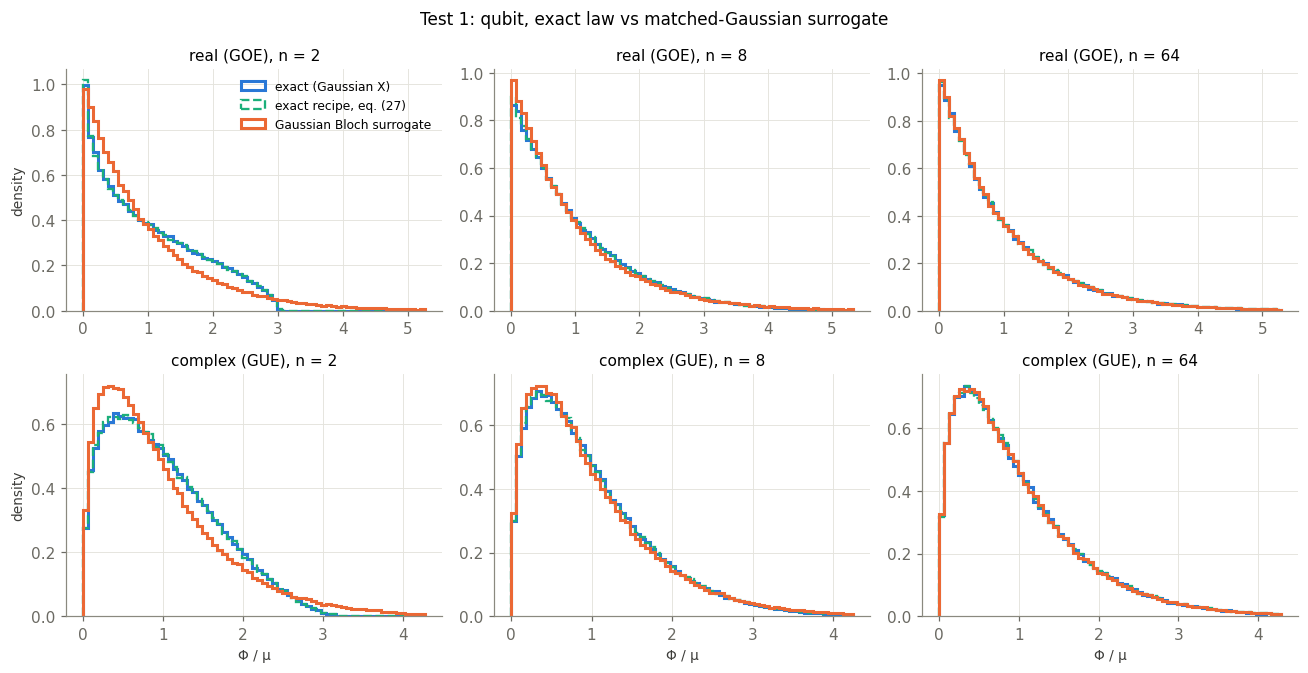

Test 1 time: 2.1 s


In [4]:
t0 = time.time()
QUBIT_N = (2, 8, 64)
N1 = n_samples(200_000)


def qubit_phi_beta_recipe(n, cplx, N):
    # Exact finite-n qubit law, PDF eq. (27): Phi = (R + R')/2 - sqrt(R R') C, R ~ Beta (eq. 26).
    a, b = (1.5, n - 1) if cplx else (1.0, (n - 1) / 2)
    R, Rp = rng.beta(a, b, size=(2, N))
    C = rng.uniform(-1, 1, N) if cplx else np.cos(rng.uniform(0, 2 * np.pi, N))
    return (R + Rp) / 2 - np.sqrt(R * Rp) * C


def qubit_phi_gaussian_surrogate(n, cplx, N):
    # Bloch vector r ~ N(0, s^2 I_k) with E|r|^2 = mu (matched mean and covariance).
    k = 3 if cplx else 2
    s2 = theory(2, n, cplx)['mu'] / k
    r = rng.normal(0.0, np.sqrt(s2), size=(2, N, k))
    phi = 0.5 * np.sum((r[0] - r[1]) ** 2, axis=1)
    return phi, np.mean(np.linalg.norm(r, axis=-1) > 1)


rows, hist1 = [], {}
for cplx in (False, True):
    for n in QUBIT_N:
        t = theory(2, n, cplx)
        ph_exact = exact_phi(2, n, cplx, N1)
        ph_beta = qubit_phi_beta_recipe(n, cplx, N1)
        ph_sur, unphys = qubit_phi_gaussian_surrogate(n, cplx, N1)

        zm, zv = mean_z(ph_exact, t['mu']), var_z(ph_exact, t['var'])
        check(f'Test 1 {ENS[cplx]}, n = {n}: exact-sample mean and variance match eq. (31)',
              abs(zm) < 4 and abs(zv) < 4, f'z_mean = {zm:+.2f}, z_var = {zv:+.2f}')
        ks_beta = stats.ks_2samp(ph_exact, ph_beta)
        check(f'Test 1 {ENS[cplx]}, n = {n}: Wishart samples and eq. (27) samples have the same law',
              ks_beta.pvalue > 1e-3, f'KS D = {ks_beta.statistic:.4f}, p = {ks_beta.pvalue:.3f}')

        rows.append({'ensemble': ENS[cplx], 'n': n, 'pairs': N1,
                     'mean (exact)': t['mu'],
                     'var (exact)': t['var'],
                     'var surrogate / exact': t['var_chi2'] / t['var'],
                     'skew exact': stats.skew(ph_exact),
                     'skew surrogate': stats.skew(ph_sur),
                     'KS D exact vs surrogate': stats.ks_2samp(ph_exact, ph_sur).statistic,
                     'surrogate |r|>1 (%)': 100 * unphys})
        hist1[(cplx, n)] = (t, ph_exact, ph_beta, ph_sur)

display(pd.DataFrame(rows).round(4))

fig, axes = plt.subplots(2, len(QUBIT_N), figsize=(12, 6.2))
for i, cplx in enumerate((False, True)):
    for j, n in enumerate(QUBIT_N):
        ax = axes[i, j]
        t, ph_exact, ph_beta, ph_sur = hist1[(cplx, n)]
        xmax = np.quantile(ph_sur / t['mu'], 0.995)
        bins = np.linspace(0, xmax, 70)
        ax.hist(ph_exact / t['mu'], bins, density=True, histtype='step', color=C_BLUE, lw=2,
                label='exact (Gaussian X)')
        ax.hist(ph_beta / t['mu'], bins, density=True, histtype='step', color=C_AQUA, lw=1.5,
                ls='--', label='exact recipe, eq. (27)')
        ax.hist(ph_sur / t['mu'], bins, density=True, histtype='step', color=C_ORANGE, lw=2,
                label='Gaussian Bloch surrogate')
        ax.set_title(f'{ENS[cplx]}, n = {n}')
        if i == 1: ax.set_xlabel('Φ / μ')
        if j == 0: ax.set_ylabel('density')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Test 1: qubit, exact law vs matched-Gaussian surrogate', fontsize=11)
fig.tight_layout(); plt.show()
print(f'Test 1 time: {time.time() - t0:.1f} s')

## Test 2: Is per-pair Φ close to χ² at the project's block sizes?

**Question.** The PDF proves Φ/EΦ → χ²_K/K only for fixed m as n → ∞ (eq. 35). The project instead sits at a fixed ratio m/n = ½: L = 9, 11, 13 with ℓ = 3, 4, 5. Is the matched-mean χ² law of eq. (36) still accurate in that regime? This is the arbitrary-d_A, d_B version of the Gaussian surrogate, with the Gaussian model applied to all K traceless coordinates of ρ_A.

**Known analytically.** The variances differ from the χ² variance by less than 1% (PDF §9 table). The χ²_K law has skewness √(8/K) and excess kurtosis 12/K.

**Checks.** Sample means and variances against eqs. (3) and (5).

**Findings:**
- KS test against (μ/K)·χ²_K.
- Skewness and kurtosis deviations, in units of the normal-theory standard error.
- A Q–Q deviation plot.

**Caveat.** With K ≥ 135, χ²_K is already close to normal, so passing this test does not tell χ² apart from other near-Gaussian laws. A simulation also cannot prove the fixed-ratio limit.

[PASS] Test 2 real (GOE), (m, n) = (16, 32): sample mean and variance match eqs. (3), (5)   (z_mean = -1.06, z_var = -0.27)
FINDING  real (GOE)    (m, n) = ( 16,  32), K =  135: KS vs chi2 D = 0.0027, p = 0.111;  skew 0.2442 vs 0.2434 (+0.1 s.e.);  ex. kurt 0.0741 vs 0.0889 (-1.4 s.e.)


[PASS] Test 2 complex (GUE), (m, n) = (16, 32): sample mean and variance match eqs. (3), (5)   (z_mean = -0.00, z_var = -0.48)
FINDING  complex (GUE) (m, n) = ( 16,  32), K =  255: KS vs chi2 D = 0.0023, p = 0.227;  skew 0.1828 vs 0.1771 (+1.0 s.e.);  ex. kurt 0.0499 vs 0.0471 (+0.3 s.e.)


[PASS] Test 2 real (GOE), (m, n) = (32, 64): sample mean and variance match eqs. (3), (5)   (z_mean = -0.72, z_var = +0.75)
FINDING  real (GOE)    (m, n) = ( 32,  64), K =  527: KS vs chi2 D = 0.0024, p = 0.604;  skew 0.1184 vs 0.1232 (-0.6 s.e.);  ex. kurt 0.0159 vs 0.0228 (-0.4 s.e.)


[PASS] Test 2 complex (GUE), (m, n) = (32, 64): sample mean and variance match eqs. (3), (5)   (z_mean = -0.20, z_var = -1.81)
FINDING  complex (GUE) (m, n) = ( 32,  64), K = 1023: KS vs chi2 D = 0.0024, p = 0.590;  skew 0.0897 vs 0.0884 (+0.2 s.e.);  ex. kurt -0.0007 vs 0.0117 (-0.8 s.e.)


[PASS] Test 2 real (GOE), (m, n) = (64, 128): sample mean and variance match eqs. (3), (5)   (z_mean = -1.02, z_var = +0.19)
FINDING  real (GOE)    (m, n) = ( 64, 128), K = 2079: KS vs chi2 D = 0.0041, p = 0.525;  skew 0.0531 vs 0.0620 (-0.7 s.e.);  ex. kurt -0.0369 vs 0.0058 (-1.7 s.e.)


[PASS] Test 2 complex (GUE), (m, n) = (64, 128): sample mean and variance match eqs. (3), (5)   (z_mean = +0.06, z_var = +0.64)
FINDING  complex (GUE) (m, n) = ( 64, 128), K = 4095: KS vs chi2 D = 0.0029, p = 0.889;  skew 0.0355 vs 0.0442 (-0.7 s.e.);  ex. kurt 0.0365 vs 0.0029 (+1.4 s.e.)


,ensemble,m,n,K,pairs,exact var / chi2 var,skew,skew chi2,skew diff (s.e.),ex.kurt,ex.kurt chi2,kurt diff (s.e.),KS D,KS p
0,real (GOE),16,32,135,200000,1.0047,0.2442,0.2434,0.1352,0.0741,0.0889,-1.3532,0.0027,0.1111
1,complex (GUE),16,32,255,200000,0.9947,0.1828,0.1771,1.0393,0.0499,0.0471,0.2633,0.0023,0.2275
2,real (GOE),32,64,527,100000,1.0051,0.1184,0.1232,-0.6267,0.0159,0.0228,-0.4434,0.0024,0.6036
3,complex (GUE),32,64,1023,100000,0.9987,0.0897,0.0884,0.1638,-0.0007,0.0117,-0.8031,0.0024,0.5902
4,real (GOE),64,128,2079,40000,1.0032,0.0531,0.0620,-0.7265,-0.0369,0.0058,-1.7433,0.0041,0.5248
5,complex (GUE),64,128,4095,40000,0.9997,0.0355,0.0442,-0.7126,0.0365,0.0029,1.3706,0.0029,0.8892


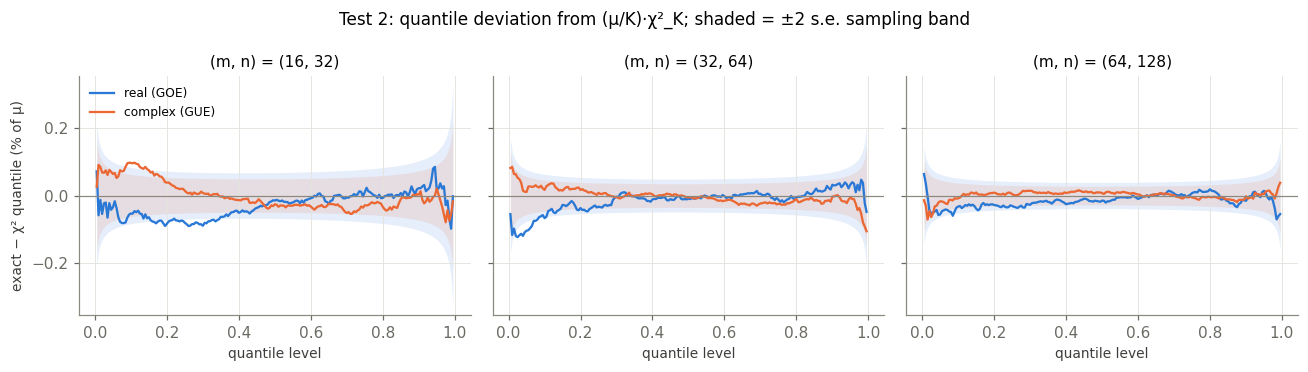

Test 2 time: 36.6 s


In [5]:
t0 = time.time()
PROJECT_SIZES = [(16, 32, 200_000), (32, 64, 100_000), (64, 128, 40_000)]   # (m, n, full pairs): L = 9, 11, 13

rows, qq = [], {}
for m, n, N_full in PROJECT_SIZES:
    N = n_samples(N_full)
    for cplx in (False, True):
        t = theory(m, n, cplx)
        ph = exact_phi(m, n, cplx, N)
        chi = stats.chi2(t['K'], scale=t['mu'] / t['K'])

        zm, zv = mean_z(ph, t['mu']), var_z(ph, t['var'])
        check(f'Test 2 {ENS[cplx]}, (m, n) = ({m}, {n}): sample mean and variance match eqs. (3), (5)',
              abs(zm) < 4 and abs(zv) < 4, f'z_mean = {zm:+.2f}, z_var = {zv:+.2f}')

        ks = stats.kstest(ph, chi.cdf)
        sk, ku = stats.skew(ph), stats.kurtosis(ph)
        sk_chi, ku_chi = np.sqrt(8 / t['K']), 12 / t['K']
        sk_se, ku_se = np.sqrt(6 / N), np.sqrt(24 / N)
        print(f"FINDING  {ENS[cplx]:13s} (m, n) = ({m:3d}, {n:3d}), K = {t['K']:4d}: "
              f"KS vs chi2 D = {ks.statistic:.4f}, p = {ks.pvalue:.3f};  "
              f"skew {sk:.4f} vs {sk_chi:.4f} ({(sk - sk_chi) / sk_se:+.1f} s.e.);  "
              f"ex. kurt {ku:.4f} vs {ku_chi:.4f} ({(ku - ku_chi) / ku_se:+.1f} s.e.)")
        rows.append({'ensemble': ENS[cplx], 'm': m, 'n': n, 'K': t['K'], 'pairs': N,
                     'exact var / chi2 var': t['var'] / t['var_chi2'],
                     'skew': sk, 'skew chi2': sk_chi, 'skew diff (s.e.)': (sk - sk_chi) / sk_se,
                     'ex.kurt': ku, 'ex.kurt chi2': ku_chi, 'kurt diff (s.e.)': (ku - ku_chi) / ku_se,
                     'KS D': ks.statistic, 'KS p': ks.pvalue})
        qq[(m, cplx)] = (ph, t, chi)

display(pd.DataFrame(rows).round(4))

# Q-Q deviation plot: (exact quantile - chi2 quantile) as % of the mean, with a +/-2 s.e. sampling band.
p = np.linspace(0.005, 0.995, 199)
fig, axes = plt.subplots(1, len(PROJECT_SIZES), figsize=(12, 3.4), sharey=True)
for ax, (m, n, _) in zip(axes, PROJECT_SIZES):
    for cplx, col in ((False, C_BLUE), (True, C_ORANGE)):
        ph, t, chi = qq[(m, cplx)]
        q_chi = chi.ppf(p)
        dev = 100 * (np.quantile(ph, p) - q_chi) / t['mu']
        se = 100 * np.sqrt(p * (1 - p) / len(ph)) / chi.pdf(q_chi) / t['mu']
        ax.fill_between(p, -2 * se, 2 * se, color=col, alpha=0.12, lw=0)
        ax.plot(p, dev, color=col, lw=1.5, label=ENS[cplx])
    ax.axhline(0, color='#8a897f', lw=0.8)
    ax.set_title(f'(m, n) = ({m}, {n})'); ax.set_xlabel('quantile level')
axes[0].set_ylabel('exact − χ² quantile (% of μ)'); axes[0].legend(fontsize=8)
fig.suptitle('Test 2: quantile deviation from (μ/K)·χ²_K; shaded = ±2 s.e. sampling band', fontsize=11)
fig.tight_layout(); plt.show()
print(f'Test 2 time: {time.time() - t0:.1f} s')

## Test 3: Null distribution of the averaged project observable

**Question.** If the eigenvectors were structureless, what spread would the project's Φ have? Here Φ means the average over middle-50% adjacent pairs and over the L − ℓ blocks. This is where "draw a state from GOE/GUE" belongs: on the full 2^L-dimensional space, not on B.

**Construction.** The eigenvectors of a GOE (GUE) matrix form a Haar-random orthogonal (unitary) basis, independent of the eigenvalues. The middle-50% window is therefore just k = 2^(L−1) Haar-random orthonormal columns.
- The default sampler draws these columns by QR decomposition of a Gaussian matrix, which is fast.
- A smaller run diagonalises actual GOE/GUE matrices, to confirm that both methods give the same null.
- Φ is evaluated with `phi_block_avg`, which is checked against a literal copy of the notebook's `_phi_l3`.

**Expectation.**
- **Mean:** μ·D/(D−1) (eq. 39), because adjacent eigenvectors are orthogonal.
- **Spread:** *larger* than the naive σ/√(pairs × blocks), for two reasons. Neighbouring pairs share a state (eqs. 40–41), and overlapping blocks are correlated (PDF §8).
- **Table columns:**
  - `eq.(41) sd / naive` shows how much of the inflation the neighbour-pair covariance alone explains.
  - `block corr` shows the remaining contribution, from correlations between block positions.

**Which null to use.**
- A real Hamiltonian, built only from ZZ, X, Z, XX, YY and XZ+ZX terms, needs the GOE null.
- XY+YX or YZ+ZY terms make H complex. Then the GUE null applies, provided no other antiunitary symmetry survives (check ⟨r⟩, as in the main notebook).

[PASS] Test 3 real (GOE): phi_block_avg reproduces the notebook _phi_l3   (0.065886531356 vs 0.065886531356)


[PASS] Test 3 complex (GUE): phi_block_avg reproduces the notebook _phi_l3   (0.062014030328 vs 0.062014030328)


[PASS] Test 3 real (GOE), L = 9, l = 3: null mean matches mu * D/(D-1), eq. (39)   (z = -1.81)
[PASS] Test 3 real (GOE), L = 9, l = 3: QR-Haar and GOE/GUE-diagonalisation nulls agree   (means z = -2.97, sd ratio eigh/qr = 0.94)
FINDING  real (GOE)    L = 9, l = 3: sd of averaged Phi = 3.666e-04 = 1.79 x naive iid estimate; Shapiro p = 0.959


[PASS] Test 3 complex (GUE), L = 9, l = 3: null mean matches mu * D/(D-1), eq. (39)   (z = -0.36)
[PASS] Test 3 complex (GUE), L = 9, l = 3: QR-Haar and GOE/GUE-diagonalisation nulls agree   (means z = -0.13, sd ratio eigh/qr = 1.04)
FINDING  complex (GUE) L = 9, l = 3: sd of averaged Phi = 2.364e-04 = 1.68 x naive iid estimate; Shapiro p = 0.792


,ensemble,L,l,m,n,draws,mean,s.e.,mu indep (3),mu orth (39),sd,naive sd,sd / naive,eq.(41) sd / naive,block corr (adjacent),block corr (all),skew,Shapiro p
0,real (GOE),9,3,16,32,1500,0.065773,0.000009,0.065661,0.065790,0.000367,0.000205,1.790111,1.224904,0.284905,0.215787,0.053771,0.959192
1,complex (GUE),9,3,16,32,1500,0.062254,0.000006,0.062135,0.062256,0.000236,0.000140,1.684643,1.222853,0.251995,0.180691,0.037243,0.791997


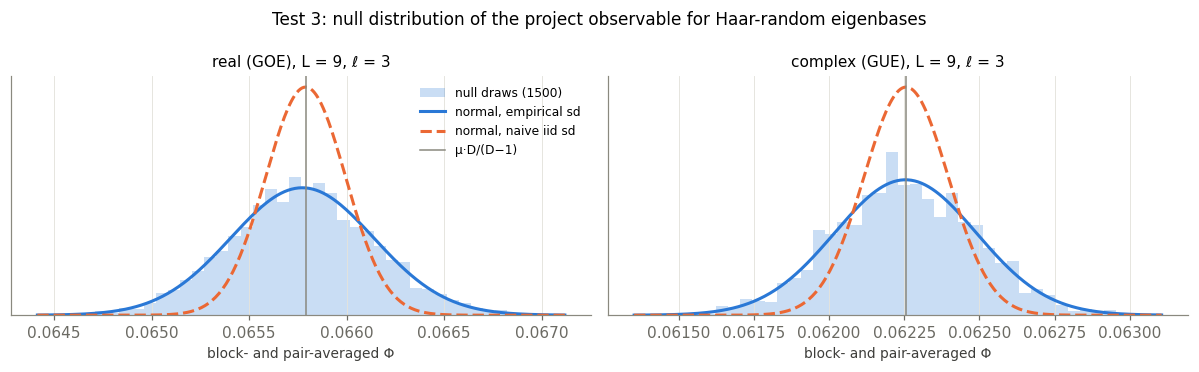

Test 3 time: 106.7 s


In [6]:
t0 = time.time()
NULL_SIZES = [(9, 3)]               # (L, l). Add (11, 4) for the L = 11 null: ~0.6 s (real) / 1.2 s (complex)
                                    # per QR draw; the GOE/GUE diagonalisation cross-check is much
                                    # slower at dim 2048, so lower R_EIGH for that size.
R_NULL = 300 if QUICK else 1500     # Haar (QR) draws per ensemble
R_EIGH = 60 if QUICK else 300       # GOE/GUE-diagonalisation draws per ensemble (cross-check)


def make_block_perms(L, l):
    perms = []
    for j in range(L - l):
        keep = list(range(j, j + l + 1))
        perms.append(keep + [k for k in range(L) if k not in keep] + [L])
    return perms


def phi_block_avg(V, L, l, perms=None, return_blocks=False):
    # The project observable (Spin_Phi_Optimization.ipynb `_phi_l3` / `_phi_l4`) for any (L, l).
    # V: (2**L, n_eig) orthonormal columns in energy order. Returns the mean over blocks and pairs.
    perms = perms or make_block_perms(L, l)
    n_eig, mb = V.shape[1], 2 ** (l + 1)
    psi_t = V.reshape([2] * L + [n_eig])
    per_block = np.empty((len(perms), n_eig - 1))
    for b, p in enumerate(perms):
        A = np.transpose(psi_t, p).reshape(mb, -1, n_eig).transpose(2, 0, 1)   # (n_eig, mb, env)
        rho = np.conj(A) @ np.swapaxes(A, -1, -2)       # same contraction as the notebook
        d = np.diff(rho, axis=0)
        per_block[b] = np.einsum('nij,nji->n', d, d).real
    return (per_block.mean(), per_block.mean(axis=1)) if return_blocks else per_block.mean()


def haar_frame(dim, k, cplx):
    # k Haar-random orthonormal columns: QR of a Gaussian matrix with the R-diagonal phases fixed.
    Q, R = np.linalg.qr(gaussian((dim, k), cplx))
    d = np.diag(R)
    return Q * (d / np.abs(d))


def goe_gue_window(dim, cplx, lo, hi):
    # Middle-window eigenvectors of an actual GOE / GUE matrix (energy ordered).
    G = gaussian((dim, dim), cplx)
    return eigh((G + np.conj(G.T)) / 2, subset_by_index=[lo, hi])[1]


def null_samples(L, l, cplx, R, method='qr'):
    dim = 2 ** L
    lo, hi = int(dim * 0.25), int(dim * 0.75) - 1          # same window as the main notebook
    perms = make_block_perms(L, l)
    vals, blocks = np.empty(R), np.empty((R, L - l))
    for r in range(R):
        V = haar_frame(dim, hi - lo + 1, cplx) if method == 'qr' else goe_gue_window(dim, cplx, lo, hi)
        vals[r], blocks[r] = phi_block_avg(V, L, l, perms, return_blocks=True)
    return vals, blocks


# ---- Literal copy of the notebook's _phi_l3 (cell 2), used only to validate phi_block_avg ----
_L, _l_block = 9, 3
_dim_block, _n_valid = 2 ** (_l_block + 1), _L - _l_block
_perms = []
for _j in range(_n_valid):
    _keep = list(range(_j, _j + _l_block + 1))
    _env = [k for k in range(_L) if k not in _keep]
    _perms.append(_keep + _env + [_L])

def _phi_l3(V_loc):
    n_eig = V_loc.shape[1]
    psi_t = V_loc.reshape([2] * _L + [n_eig])
    total = 0.0
    for _j in range(_n_valid):
        psi_p = np.transpose(psi_t, _perms[_j])
        psi_mat = psi_p.reshape(_dim_block, -1, n_eig)
        rho_all = np.einsum('ien,jen->nij', psi_mat.conj(), psi_mat)
        delta = np.diff(rho_all, axis=0)
        total += np.einsum('nij,nji->n', delta, delta).real.sum()
    return total / (_n_valid * (n_eig - 1))

for cplx in (False, True):
    V_test = haar_frame(2 ** 9, 256, cplx)
    a_, b_ = phi_block_avg(V_test, 9, 3), _phi_l3(V_test)
    check(f'Test 3 {ENS[cplx]}: phi_block_avg reproduces the notebook _phi_l3',
          np.isclose(a_, b_, rtol=1e-12, atol=0), f'{a_:.12f} vs {b_:.12f}')

# ---- Null ensembles --------------------------------------------------------------
NULL, rows = {}, []
for (L, l) in NULL_SIZES:
    dim, m = 2 ** L, 2 ** (l + 1)
    n, n_pairs, n_blocks = dim // m, dim // 2 - 1, L - l
    for cplx in (False, True):
        t = theory(m, n, cplx)
        vals, blocks = null_samples(L, l, cplx, R_NULL, 'qr')
        vals_e, _ = null_samples(L, l, cplx, R_EIGH, 'eigh')
        NULL[(L, l, cplx)] = dict(vals=vals, blocks=blocks, vals_eigh=vals_e, theory=t)

        se = vals.std(ddof=1) / np.sqrt(R_NULL)
        z = (vals.mean() - t['mu_orth']) / se
        check(f'Test 3 {ENS[cplx]}, L = {L}, l = {l}: null mean matches mu * D/(D-1), eq. (39)',
              abs(z) < 4, f'z = {z:+.2f}')
        se_e = vals_e.std(ddof=1) / np.sqrt(R_EIGH)
        z_e = (vals.mean() - vals_e.mean()) / np.hypot(se, se_e)
        check(f'Test 3 {ENS[cplx]}, L = {L}, l = {l}: QR-Haar and GOE/GUE-diagonalisation nulls agree',
              abs(z_e) < 4, f'means z = {z_e:+.2f}, sd ratio eigh/qr = {vals_e.std(ddof=1) / vals.std(ddof=1):.2f}')

        sd = vals.std(ddof=1)
        naive = np.sqrt(t['var'] / (n_pairs * n_blocks))
        eq41 = np.sqrt((n_pairs * t['var'] + 2 * (n_pairs - 1) * t['vP']) / n_pairs ** 2 / n_blocks)
        C = np.corrcoef(blocks.T)
        print(f"FINDING  {ENS[cplx]:13s} L = {L}, l = {l}: sd of averaged Phi = {sd:.3e} "
              f"= {sd / naive:.2f} x naive iid estimate; Shapiro p = {stats.shapiro(vals).pvalue:.3f}")
        rows.append({'ensemble': ENS[cplx], 'L': L, 'l': l, 'm': m, 'n': n, 'draws': R_NULL,
                     'mean': vals.mean(), 's.e.': se, 'mu indep (3)': t['mu'], 'mu orth (39)': t['mu_orth'],
                     'sd': sd, 'naive sd': naive, 'sd / naive': sd / naive, 'eq.(41) sd / naive': eq41 / naive,
                     'block corr (adjacent)': np.mean(np.diag(C, 1)),
                     'block corr (all)': C[np.triu_indices_from(C, 1)].mean(),
                     'skew': stats.skew(vals), 'Shapiro p': stats.shapiro(vals).pvalue})

display(pd.DataFrame(rows).round(6))

fig, axes = plt.subplots(len(NULL_SIZES), 2, figsize=(11, 3.4 * len(NULL_SIZES)), squeeze=False)
for i, (L, l) in enumerate(NULL_SIZES):
    for j, cplx in enumerate((False, True)):
        ax, d = axes[i, j], NULL[(L, l, cplx)]
        vals, t = d['vals'], d['theory']
        n_pairs, n_blocks = 2 ** (L - 1) - 1, L - l
        naive = np.sqrt(t['var'] / (n_pairs * n_blocks))
        x = np.linspace(vals.min() - 0.3 * vals.std(), vals.max() + 0.3 * vals.std(), 300)
        ax.hist(vals, 40, density=True, color=C_BLUE, alpha=0.25, lw=0, label=f'null draws ({len(vals)})')
        ax.plot(x, stats.norm.pdf(x, vals.mean(), vals.std(ddof=1)), color=C_BLUE, label='normal, empirical sd')
        ax.plot(x, stats.norm.pdf(x, t['mu_orth'], naive), color=C_ORANGE, ls='--', label='normal, naive iid sd')
        ax.axvline(t['mu_orth'], color='#8a897f', lw=1, label='μ·D/(D−1)')
        ax.set_title(f'{ENS[cplx]}, L = {L}, ℓ = {l}'); ax.set_xlabel('block- and pair-averaged Φ')
        ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle('Test 3: null distribution of the project observable for Haar-random eigenbases', fontsize=11)
fig.tight_layout(); plt.show()
print(f'Test 3 time: {time.time() - t0:.1f} s')

### Test 3b: Larger cross-check of the two samplers

In the reference run of Test 3, the real-case means from the QR sampler and from GOE diagonalisation differed by z ≈ −3, close to the |z| < 4 limit. The two samplers are identical in distribution, since GOE eigenvectors are Haar-distributed and independent of the eigenvalues. So this cell draws 2,000 independent samples of each (200 with `QUICK = True`) and checks that their means agree with each other and with μ·D/(D−1).

It uses its own random generator (seed 777), so the other tests' results don't change.

In [7]:
t0 = time.time()
rng_b = np.random.default_rng(777)
L_b, l_b = 9, 3
dim_b = 2 ** L_b
lo_b, hi_b = dim_b // 4, 3 * dim_b // 4 - 1
perms_b = make_block_perms(L_b, l_b)
R_B = 200 if QUICK else 2000
v_eigh, v_qr = np.empty(R_B), np.empty(R_B)
for r in range(R_B):
    G = rng_b.standard_normal((dim_b, dim_b))
    v_eigh[r] = phi_block_avg(eigh((G + G.T) / 2, subset_by_index=[lo_b, hi_b])[1], L_b, l_b, perms_b)
    Q, Rm = np.linalg.qr(rng_b.standard_normal((dim_b, hi_b - lo_b + 1)))
    v_qr[r] = phi_block_avg(Q * np.sign(np.diag(Rm)), L_b, l_b, perms_b)

t_b = theory(2 ** (l_b + 1), dim_b // 2 ** (l_b + 1), False)
rows = []
for name, v in (('GOE diagonalisation', v_eigh), ('QR (Haar)', v_qr)):
    se = v.std(ddof=1) / np.sqrt(R_B)
    z = (v.mean() - t_b['mu_orth']) / se
    check(f'Test 3b {name}: mean matches mu * D/(D-1) with {R_B} draws', abs(z) < 4, f'z = {z:+.2f}')
    rows.append({'sampler': name, 'draws': R_B, 'mean': v.mean(), 's.e.': se, 'mu orth (39)': t_b['mu_orth'],
                 'z vs mu orth': z, 'sd': v.std(ddof=1)})
z_d = (v_eigh.mean() - v_qr.mean()) / np.hypot(v_eigh.std(ddof=1), v_qr.std(ddof=1)) * np.sqrt(R_B)
check('Test 3b: GOE-diagonalisation and QR means agree', abs(z_d) < 4, f'z = {z_d:+.2f}')
display(pd.DataFrame(rows).round(7))
print(f'Test 3b time: {time.time() - t0:.1f} s')

[PASS] Test 3b GOE diagonalisation: mean matches mu * D/(D-1) with 2000 draws   (z = +0.25)
[PASS] Test 3b QR (Haar): mean matches mu * D/(D-1) with 2000 draws   (z = +0.42)
[PASS] Test 3b: GOE-diagonalisation and QR means agree   (z = -0.13)


,sampler,draws,mean,s.e.,mu orth (39),z vs mu orth,sd
0,GOE diagonalisation,2000,0.065792,0.000008,0.06579,0.254578,0.000350
1,QR (Haar),2000,0.065794,0.000008,0.06579,0.420439,0.000372


Test 3b time: 155.4 s


## Test 4: Using the null, a Hamiltonian vs structureless eigenvectors

This test builds the PRX-point mixed-field Ising chain, (g, h) = (1.08, 0.30), using the main notebook's conventions:

H = Σ ZᵢZᵢ₊₁ + g ΣXᵢ + h ΣZᵢ + 0.25 Z₀ − 0.25 Z_{L−1}

It computes Φ for ℓ = 3 and compares it with the GOE null from test 3. The output gives:
- the ratio Φ_H / ⟨Φ_null⟩,
- the z-score,
- the null's 95% band for that ratio,
- the fraction of null draws at or above Φ_H.

To test another Hamiltonian, pass Φ from its middle-50% eigenvectors to `compare_to_null`. Use the null that matches its symmetry class.

The null only says whether Φ_H can be distinguished from structureless eigenvectors. It says nothing about *why* Φ_H is larger (PDF §9).

In [8]:
def build_mfim(L, g, h, left_edge=0.25, right_edge=-0.25):
    # H = sum Z_i Z_{i+1} + g sum X_i + h sum Z_i + left_edge Z_0 + right_edge Z_{L-1}
    # (same convention as build_hamiltonian_components in Spin_Phi_Optimization.ipynb).
    sx, sz, I2 = np.array([[0., 1.], [1., 0.]]), np.diag([1., -1.]), np.eye(2)
    def op(single):                       # single: {site: 2x2 operator}
        return reduce(np.kron, [single.get(i, I2) for i in range(L)])
    H = sum(op({i: sz, i + 1: sz}) for i in range(L - 1))
    H = H + g * sum(op({i: sx}) for i in range(L)) + h * sum(op({i: sz}) for i in range(L))
    return H + left_edge * op({0: sz}) + right_edge * op({L - 1: sz})


def compare_to_null(phi_H, null_vals):
    mu, sd = null_vals.mean(), null_vals.std(ddof=1)
    lo, hi = np.quantile(null_vals / mu, [0.025, 0.975])
    return dict(phi_H=phi_H, null_mean=mu, null_sd=sd, ratio=phi_H / mu, z=(phi_H - mu) / sd,
                null_ratio_95=(lo, hi), frac_null_at_or_above=np.mean(null_vals >= phi_H))


L4, l4, g4, h4 = 9, 3, 1.08, 0.30
H = build_mfim(L4, g4, h4)
check('Test 4: PRX Hamiltonian is real symmetric, so the GOE null applies', np.isrealobj(H) and np.allclose(H, H.T))
dim = 2 ** L4
_, V_H = eigh(H, subset_by_index=[int(dim * 0.25), int(dim * 0.75) - 1])
phi_H = phi_block_avg(V_H, L4, l4)
check('Test 4: PRX Phi matches the main notebook (Phi x "ratio vs PRX" in its DE log = 0.09814)',
      np.isclose(phi_H, 0.09814, rtol=1e-3), f'Phi_H = {phi_H:.6f}')
res = compare_to_null(phi_H, NULL[(L4, l4, False)]['vals'])

print(f"PRX point (g, h) = ({g4}, {h4}), L = {L4}, l = {l4}")
print(f"  Phi_H                       = {res['phi_H']:.6f}")
print(f"  GOE null mean +/- sd        = {res['null_mean']:.6f} +/- {res['null_sd']:.2e}")
print(f"  ratio Phi_H / null mean     = {res['ratio']:.4f}   (null 95% band for this ratio: "
      f"{res['null_ratio_95'][0]:.4f} - {res['null_ratio_95'][1]:.4f})")
print(f"  z-score vs null             = {res['z']:+.1f}")
print(f"  null draws at or above Phi_H: {res['frac_null_at_or_above']:.4f}")

[PASS] Test 4: PRX Hamiltonian is real symmetric, so the GOE null applies
[PASS] Test 4: PRX Phi matches the main notebook (Phi x "ratio vs PRX" in its DE log = 0.09814)   (Phi_H = 0.098138)
PRX point (g, h) = (1.08, 0.3), L = 9, l = 3
  Phi_H                       = 0.098138
  GOE null mean +/- sd        = 0.065773 +/- 3.67e-04
  ratio Phi_H / null mean     = 1.4921   (null 95% band for this ratio: 0.9892 - 1.0112)
  z-score vs null             = +88.3
  null draws at or above Phi_H: 0.0000


## Results of the reference run

Settings: `QUICK = False`, seed 20261123. The run took 5.1 minutes, and all 40 checks passed.

**Test 0: a product state measures only what you put on A.**
- Pure product states give ⟨Φ⟩ = 0.9998 (real) and 0.9963 (complex). Eq. (29) predicts 1, and the result does not depend on what is drawn on B.
- Entangled states with the same n_B = 32 give 0.0609 and 0.0464. Eq. (31) predicts 0.0606 and 0.0462.

**Test 1: the Gaussian Bloch surrogate is only the large-n χ² limit.**
- The mean matches by construction. The variance is too large by:

  | n | real | complex |
  |---|---|---|
  | 2 | 67% | 56% |
  | 8 | 22% | 15% |
  | 64 | 3% | 2% |

- The surrogate's skewness stays at the χ²_k value (about 2.0 for real, 1.63 for complex). The exact skewness at n = 2 is 0.61 (real) and 0.65 (complex).
- At n = 2, 22% (real) and 17% (complex) of surrogate Bloch vectors lie outside the Bloch ball, so they are not valid states.
- The Wishart samples and the eq. (27) recipe agree in all six cases, which confirms that the exact qubit law is eq. (27).

**Test 2: at m/n = ½ the matched χ² law cannot be told apart from the exact per-pair law at 4×10⁴ to 2×10⁵ samples.**
- KS p-values range from 0.11 to 0.89.
- Skewness is within about 1 standard error of the χ² value, and excess kurtosis within 1.8.
- The exact and χ² variances differ by at most 0.53% (analytic).

This supports eq. (36) in the project regime at this resolution, but it is not a proof. With K ≥ 135 the χ² law is itself close to normal.

**Test 3: null distribution of the project observable (L = 9, ℓ = 3).**

| Null | Mean | μ·D/(D−1) | sd | sd / naive iid estimate |
|---|---|---|---|---|
| GOE | 0.065773 ± 0.000009 | 0.065790 | 3.67×10⁻⁴ | 1.79 |
| GUE | 0.062254 ± 0.000006 | 0.062256 | 2.36×10⁻⁴ | 1.68 |

- **Why the spread is inflated:** neighbour-pair covariance (eq. 41) accounts for a factor of 1.22. The rest comes from correlations between overlapping blocks; the correlation between adjacent block positions is about 0.25–0.28.
- **Shape:** the averaged statistic is consistent with a normal distribution (Shapiro p = 0.96 for GOE, 0.79 for GUE).
- **QR vs diagonalisation in this run:** for GOE, the two nulls' means differ by z = −2.97. Test 3b, with 2,000 draws of each, gives z = −0.13, and both means lie within 0.5 standard errors of μ·D/(D−1) (z = +0.25 and +0.42). The difference here is sampling noise.

**Test 4: PRX point, (g, h) = (1.08, 0.30).**
- Φ_H = 0.098138, which matches the main notebook.
- This is **1.49× the GOE null mean**, at z = +88. The null's 95% band for this ratio is 0.989–1.011.
- The null's relative spread is about 0.56%. That is the uncertainty to attach to any "Hamiltonian / random baseline" ratio at L = 9, ℓ = 3.

**What these tests do not address.** None of them explains *why* Φ_H exceeds the null. The structureless ensemble has no energy constraint, no locality and no energy ordering (PDF §9). The natural next surrogates each add one of these ingredients. One example is random states restricted to an energy window of H.

## Summary of checks

In [9]:
df_checks = pd.DataFrame(CHECKS, columns=['check', 'passed', 'detail'])
with pd.option_context('display.max_colwidth', 120):
    display(df_checks)
n_fail = int((~df_checks['passed']).sum())
print(f"{len(df_checks) - n_fail}/{len(df_checks)} checks passed; total run time {time.time() - T_START:.0f} s")

,check,passed,detail
0,"Formulas: real qubit n=8 gives mean 2/9, var 4/99 (eq. 31)",True,
1,"Formulas: complex qubit n=8 gives mean 3/17, var 99/5491 (eq. 31)",True,
2,"Formulas: project baseline means for (m, n) = (16, 32) match PDF §9 table",True,
3,"Formulas: project baseline means for (m, n) = (32, 64) match PDF §9 table",True,
4,"Formulas: project baseline means for (m, n) = (64, 128) match PDF §9 table",True,
5,Test 0a real (GOE): Tr_B[rho_A (x) |psi_B><psi_B|] = rho_A for 5 GOE/GUE draws of psi_B,True,
6,Test 0a complex (GUE): Tr_B[rho_A (x) |psi_B><psi_B|] = rho_A for 5 GOE/GUE draws of psi_B,True,
7,"Test 0b real (GOE), pure product |a>|b>: sample mean and variance match theory",True,"z_mean = -0.03, z_var = -1.16"
8,"Test 0b real (GOE), entangled sum_i |i>|x_i>: sample mean and variance match theory",True,"z_mean = +0.64, z_var = -0.35"
9,"Test 0b complex (GUE), pure product |a>|b>: sample mean and variance match theory",True,"z_mean = -0.92, z_var = -0.29"


40/40 checks passed; total run time 307 s
